In [40]:
from astropy import units
from astropy.time import Time
from astropy.visualization import quantity_support

from matplotlib import pyplot

import numpy 

from selflensing.fitting import self_lensing_system_from_fit
from selflensing.generators import LightcurveGenerator, RVGenerator, GPLightcurveGenerator
from selflensing.models import SelfLensingSystem

from selflensing.gp import TESSGP
from selflensing.peaks import detect_peaks


In [41]:
quantity_support()

<astropy.visualization.units.quantity_support.<locals>.MplQuantityConverter at 0x135f3f230>

In [42]:
LENSING_METHOD = 'IntegratedWittMao'

In [43]:
sls = SelfLensingSystem(
    a=5 * units.AU,
    i=(0.5*numpy.pi - 0.0001) * units.rad,
    Macc=5*units.M_sun,
    Mcomp=1 * units.M_sun,
    e=0 * units.dimensionless_unscaled,
    d=1*units.kpc,
)
sls.porb, sls.tau_eff

(Quantity(Array(1667.16202108, dtype=float64), unit='d'),
 Quantity(Array(0.59666736, dtype=float64), unit='d'))

In [44]:
start_time = Time("2025-01-01")
end_time = Time("2025-01-27")

In [45]:
lcg = GPLightcurveGenerator(sls, start_time=start_time, end_time=end_time, ev=True, db=True, sl=True, lensing_method=LENSING_METHOD, bins=27*24*6, gp=TESSGP)

In [46]:
peak_t = numpy.array(lcg.times.jd, dtype=float, copy=True)
peak_flux = numpy.array(lcg.flux_array, dtype=float, copy=True)
peak_sigma = numpy.array(numpy.sqrt(lcg.gp.model.variance), dtype=float, copy=True)

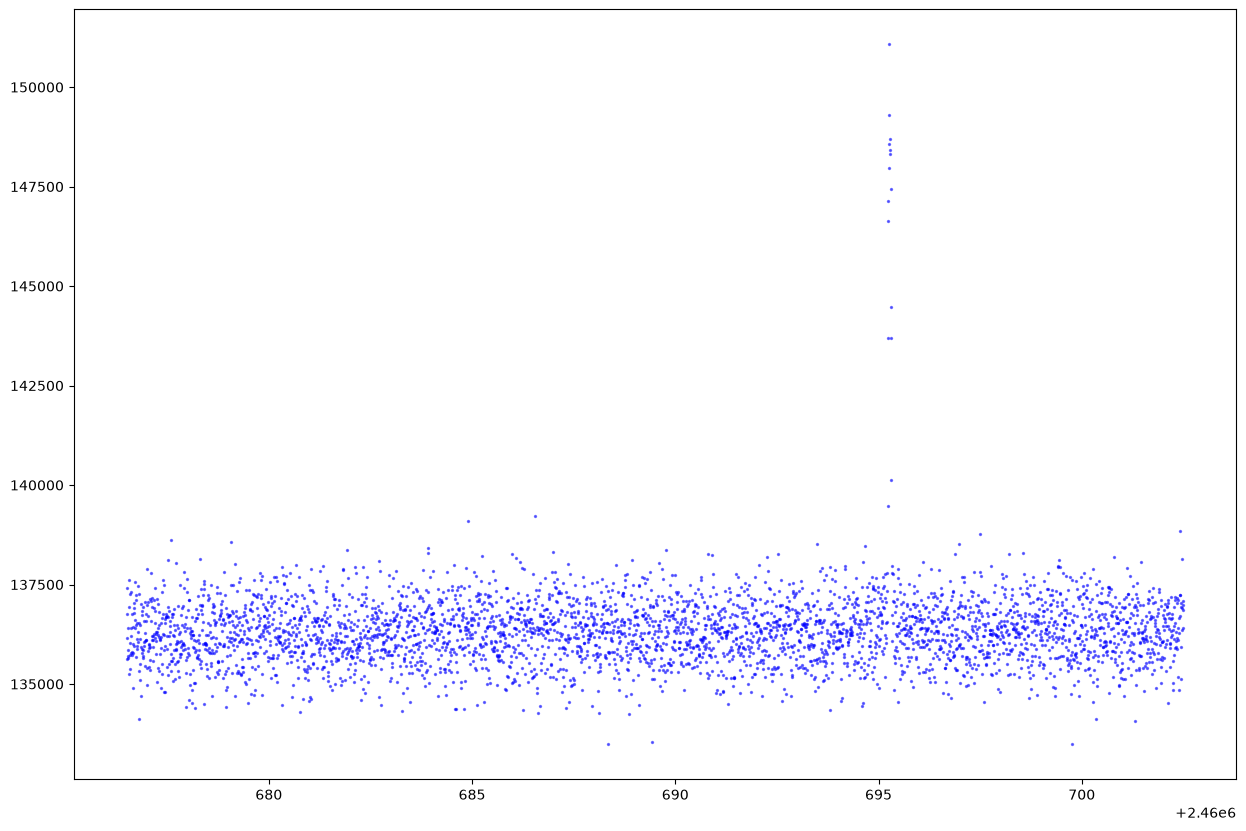

In [47]:
pyplot.figure(figsize=(15,10))
pyplot.scatter(peak_t, peak_flux, s=2, alpha=0.5, c="blue")

[PeakDetection(index=2782, time=2460695.1086956523, width=0.4, amplitude=1698.1490501493643, amplitude_err=87.37477761967614, amplitude_snr=19.435231727181574, delta_chi2=377.72743659211756, p_value=3.8881039190447712e-84, baseline_intercept=136181.06270015743, baseline_slope=56.174741135740696, window_start=2460693.1086956523, window_end=2460697.1086956523, n_points=599)]

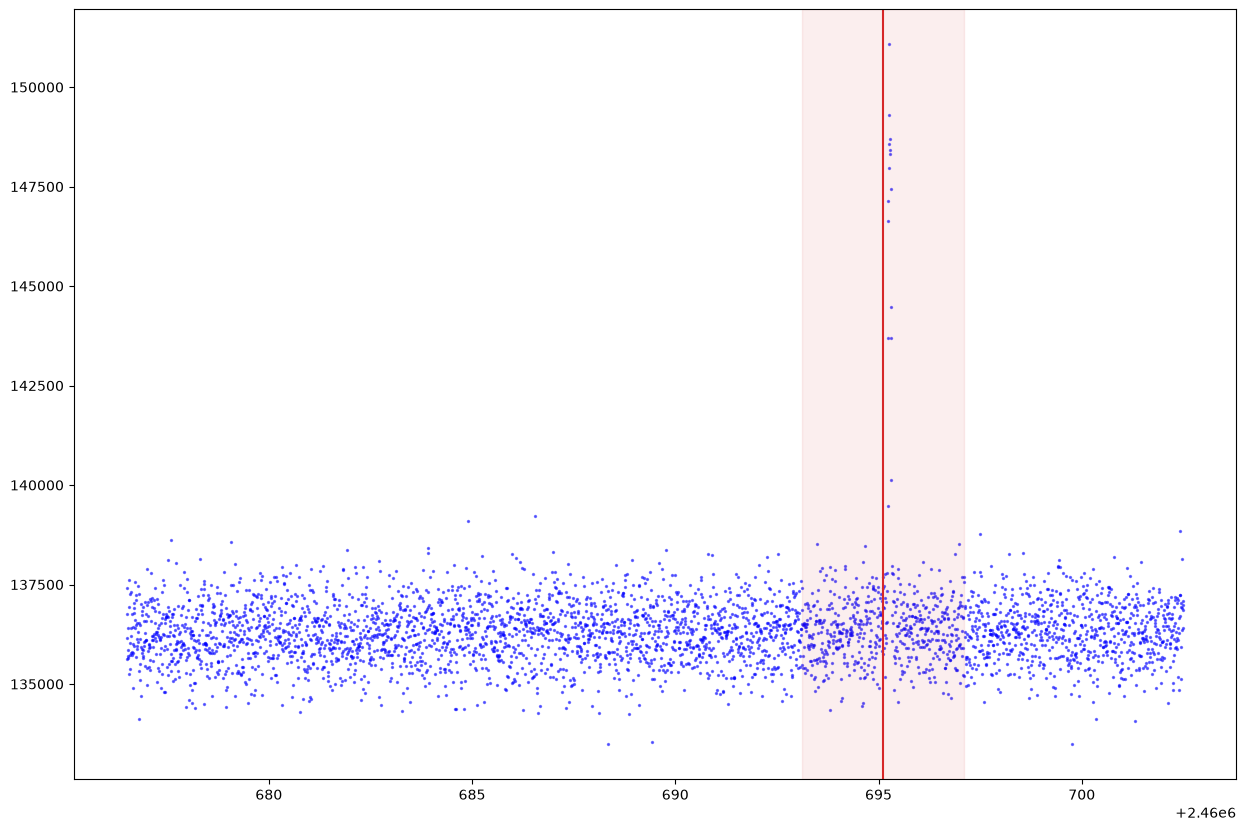

In [48]:
detections = detect_peaks(
    peak_t,
    peak_flux,
    peak_sigma,
    widths=numpy.array([0.05, 0.1, 0.2, 0.4]),
    candidate_prominence=2.5 * numpy.median(numpy.abs(peak_flux - numpy.median(peak_flux))),
    min_delta_chi2=25,
    min_amplitude_snr=5,
    max_peaks=5,
)

pyplot.figure(figsize=(15,10))
pyplot.scatter(peak_t, peak_flux, s=2, alpha=0.5, c="blue")
for peak in detections:
    pyplot.axvline(peak.time, color="tab:red")
    pyplot.axvspan(peak.window_start, peak.window_end, color="tab:red", alpha=0.08)

detections
